# Experiment 020: analysis plots

These plots complete the restarted continuation comparison for all three 0.5B seeds. Experiments 018, 019 and 020 restore the exact step-500 state and apply 499 nonzero updates under the revived learning-rate schedule. The continuations were chosen after earlier test results were known, so the comparison is exploratory and does not replace a clean 1000-step run planned from the start.

In [1]:
import json, os, sys
ROOT = '..' if os.path.basename(os.getcwd()) == 'notebooks' else '.'
sys.path.insert(0, os.path.abspath(ROOT))
import matplotlib.pyplot as plt
import numpy as np
from analysis.plotting import heatmap_text_color
from analysis.stats import _read_preds, align_pred_rows
from data.subjects import tier_of, TIERS

R = os.path.join(ROOT, 'results')
FIGDIR = os.path.join(ROOT, 'analysis', 'figures', '020_1')
os.makedirs(FIGDIR, exist_ok=True)

def accuracy(path):
    rows = _read_preds(path)
    assert len(rows) == 1884, f'{path}: expected 1884 rows, found {len(rows)}'
    return sum(r['correct'] for r in rows) / len(rows)

def paired_rows(old_path, new_path):
    old, new = align_pred_rows(_read_preds(old_path), _read_preds(new_path))
    assert len(old) == len(new) == 1884
    return old, new

# load the saved artifacts used in every comparison
new_runs = {
    0: '020_ext_B05_seed0_step1000',
    1: '018_ext_B05_seed1_step1000',
    2: '019_ext_B05_seed2_step1000',
}
paths = {}
for seed, new_run in new_runs.items():
    paths[seed] = {
        'step500': f'{R}/006_COLAB_FULL_B05_sft_grpo_seed{seed}/grpo_preds.jsonl',
        'step1000': f'{R}/{new_run}/grpo_preds.jsonl',
        'summary': f'{R}/{new_run}/comparison_summary.json',
        'curve': f'{R}/{new_run}/combined_reward_curve.json',
        'trainlog': f'{R}/{new_run}/grpo_trainlog.json',
    }
    p = paths[seed]
    p['stats'] = json.load(open(p['summary']))
    p['rows500'], p['rows1000'] = paired_rows(p['step500'], p['step1000'])
    p['acc500'] = accuracy(p['step500'])
    p['acc1000'] = accuracy(p['step1000'])
    measured_delta = p['acc1000'] - p['acc500']
    assert abs(measured_delta - p['stats']['delta']) < 1e-12

mcsft_scores = [accuracy(f'{R}/007_p8_COLAB_FULL_B05_sft_only_seed{s}/sft_preds.jsonl') for s in (0, 1, 2)]
mcsft_mean = sum(mcsft_scores) / len(mcsft_scores)
base_probe = accuracy(f'{R}/base_evals/006_COLAB_FULL_B05/base_logprob_preds.jsonl')
for seed in paths:
    print(f'seed {seed}: {paths[seed]["acc500"]:.3f} -> {paths[seed]["acc1000"]:.3f}, delta {paths[seed]["stats"]["delta"]:+.3f}')
print(f'mc-sft mean {mcsft_mean:.3f}, range {min(mcsft_scores):.3f}-{max(mcsft_scores):.3f}, base probe {base_probe:.3f}')

seed 0: 0.462 -> 0.537, delta +0.074
seed 1: 0.315 -> 0.515, delta +0.200
seed 2: 0.506 -> 0.538, delta +0.032
mc-sft mean 0.534, range 0.530-0.538, base probe 0.567


## Accuracy-reward trajectories

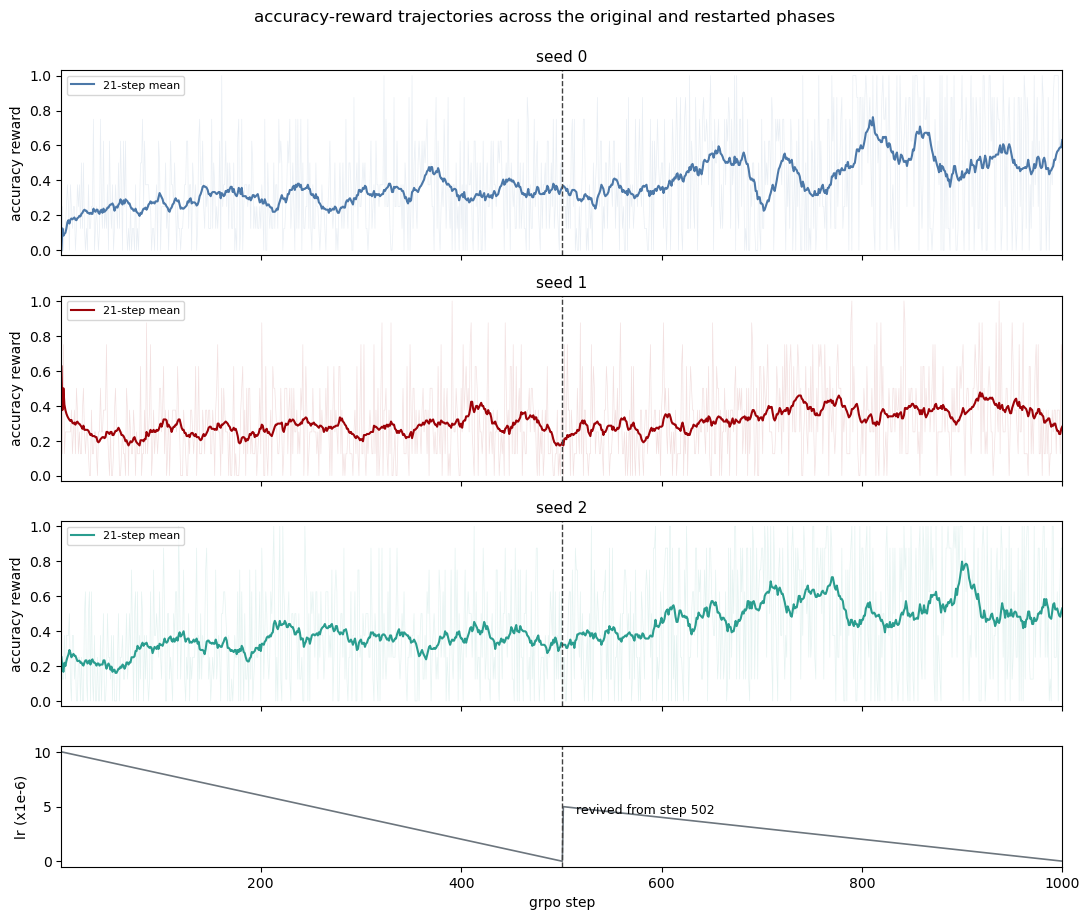

In [2]:
# plot all three accuracy-reward trajectories with the shared learning-rate schedule
def rolling(values, window=21):
    return [sum(values[max(0, i-window+1):i+1]) / len(values[max(0, i-window+1):i+1])
            for i in range(len(values))]

curves = {}
steps = list(range(1, 1001))
for seed in paths:
    raw = json.load(open(paths[seed]['curve']))
    assert sorted(int(s) for s in raw) == steps
    curves[seed] = [raw[str(s)] for s in steps]
trainlog = json.load(open(paths[0]['trainlog']))
lr = {int(e['step']): float(e['learning_rate']) for e in trainlog if 'step' in e and 'learning_rate' in e}
assert sorted(lr) == steps

fig, axes = plt.subplots(4, 1, figsize=(11, 9.2), sharex=True,
                         gridspec_kw={'height_ratios': [1, 1, 1, 0.65]})
colours = {0: '#4c78a8', 1: '#9d0208', 2: '#2a9d8f'}
for ax, seed in zip(axes[:3], (0, 1, 2)):
    ax.plot(steps, curves[seed], color=colours[seed], lw=0.5, alpha=0.12)
    ax.plot(steps, rolling(curves[seed]), color=colours[seed], lw=1.5, label='21-step mean')
    ax.axvline(500.5, color='0.25', ls='--', lw=1)
    ax.set_ylabel('accuracy reward')
    ax.set_ylim(-0.03, 1.03)
    ax.set_title(f'seed {seed}', fontsize=11)
    ax.legend(loc='upper left', fontsize=8)
axes[3].plot(steps, [lr[s] * 1e6 for s in steps], color='#6c757d', lw=1.2)
axes[3].axvline(500.5, color='0.25', ls='--', lw=1)
axes[3].text(515, 4.35, 'revived from step 502', fontsize=9)
axes[3].set_ylabel('lr (x1e-6)')
axes[3].set_xlabel('grpo step')
axes[3].set_xlim(1, 1000)
fig.suptitle('accuracy-reward trajectories across the original and restarted phases', y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_recovery_curves.png'), dpi=200, bbox_inches='tight')
plt.show()

## Accuracy endpoints and seed spread

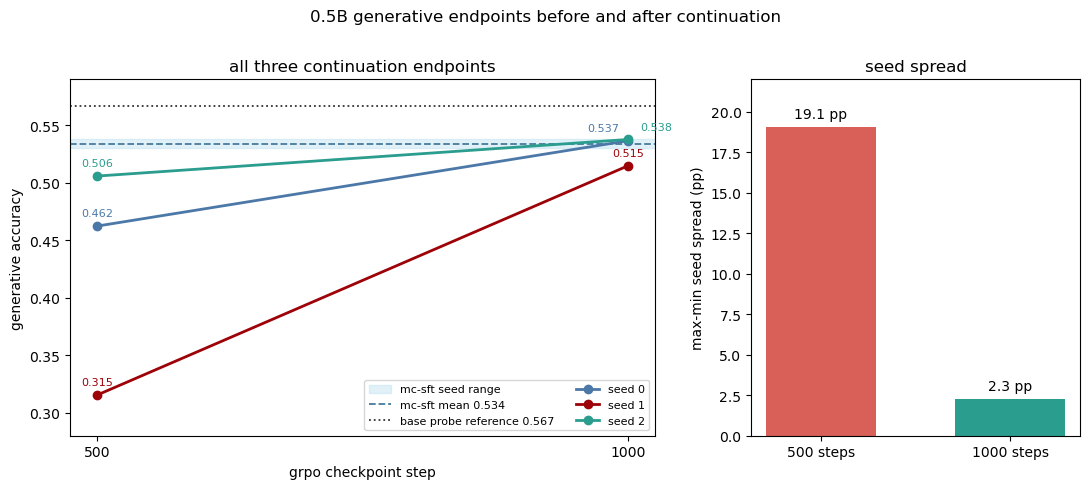

In [3]:
# compare every seed before and after the restarted phase
acc500 = [paths[s]['acc500'] for s in (0, 1, 2)]
acc1000 = [paths[s]['acc1000'] for s in (0, 1, 2)]
spread500 = (max(acc500) - min(acc500)) * 100
spread1000 = (max(acc1000) - min(acc1000)) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={'width_ratios': [1.6, 0.9]})
ax1.axhspan(min(mcsft_scores), max(mcsft_scores), color='#8ecae6', alpha=0.25, label='mc-sft seed range')
ax1.axhline(mcsft_mean, color='#457b9d', ls='--', lw=1.3, label=f'mc-sft mean {mcsft_mean:.3f}')
ax1.axhline(base_probe, color='0.2', ls=':', lw=1.3, label=f'base probe reference {base_probe:.3f}')
for seed in (0, 1, 2):
    values = [paths[seed]['acc500'], paths[seed]['acc1000']]
    ax1.plot([500, 1000], values, color=colours[seed], lw=2, marker='o', label=f'seed {seed}')
    for step, value in zip((500, 1000), values):
        label_offset = (-18, 7) if step == 1000 and seed == 0 else ((20, 7) if step == 1000 and seed == 2 else (0, 7))
        ax1.annotate(f'{value:.3f}', (step, value), xytext=label_offset, textcoords='offset points',
                     ha='center', fontsize=8, color=colours[seed])
ax1.set_xticks([500, 1000])
ax1.set_xlabel('grpo checkpoint step')
ax1.set_ylabel('generative accuracy')
ax1.set_ylim(0.28, 0.59)
ax1.set_title('all three continuation endpoints')
ax1.legend(fontsize=8, loc='lower right', ncol=2)

bars = ax2.bar(['500 steps', '1000 steps'], [spread500, spread1000], color=['#d95f59', '#2a9d8f'], width=0.58)
ax2.bar_label(bars, labels=[f'{spread500:.1f} pp', f'{spread1000:.1f} pp'], padding=4, fontsize=10)
ax2.set_ylabel('max-min seed spread (pp)')
ax2.set_ylim(0, 22)
ax2.set_title('seed spread')
fig.suptitle('0.5B generative endpoints before and after continuation', y=1.01)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_endpoints_and_spread.png'), dpi=200, bbox_inches='tight')
plt.show()

## Paired effect sizes

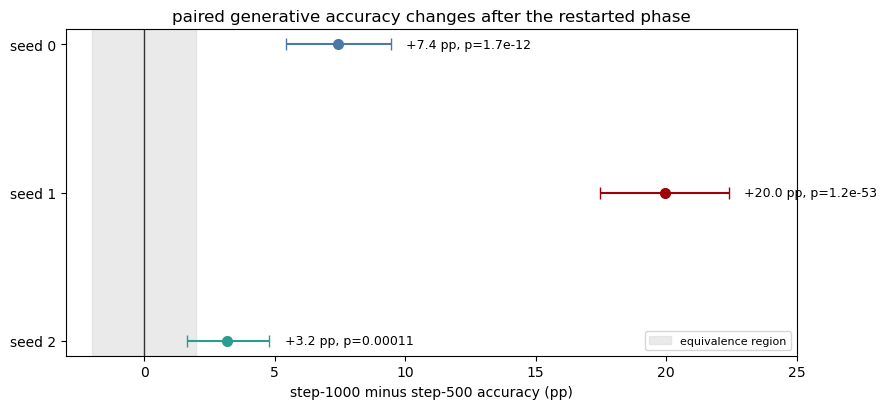

In [4]:
# plot paired generative changes with bootstrap confidence intervals
seeds = [0, 1, 2]
y = np.array([2, 1, 0])
deltas = np.array([paths[s]['stats']['delta'] * 100 for s in seeds])
lo = np.array([paths[s]['stats']['ci'][0] * 100 for s in seeds])
hi = np.array([paths[s]['stats']['ci'][1] * 100 for s in seeds])
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.axvspan(-2, 2, color='0.85', alpha=0.55, label='equivalence region')
ax.axvline(0, color='0.2', lw=1)
for i, seed in enumerate(seeds):
    ax.errorbar(deltas[i], y[i], xerr=[[deltas[i] - lo[i]], [hi[i] - deltas[i]]],
                fmt='o', ms=7, capsize=4, color=colours[seed])
    ax.text(hi[i] + 0.6, y[i], f'{deltas[i]:+.1f} pp, p={paths[seed]["stats"]["p"]:.2g}',
            va='center', fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels([f'seed {s}' for s in seeds])
ax.set_xlabel('step-1000 minus step-500 accuracy (pp)')
ax.set_xlim(-3, 25)
ax.set_title('paired generative accuracy changes after the restarted phase')
ax.legend(fontsize=8, loc='lower right')
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_paired_effects.png'), dpi=200, bbox_inches='tight')
plt.show()

## Generative and probe changes

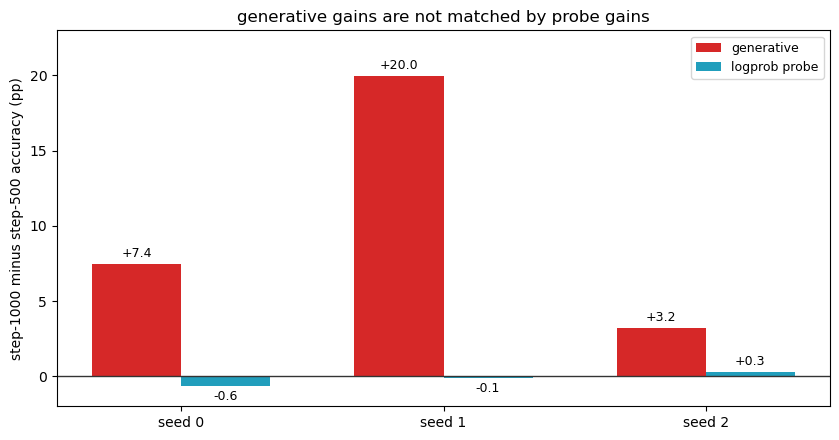

In [5]:
# place the generative and probe changes beside each other
x = np.arange(3)
width = 0.34
gen_delta = [paths[s]['stats']['delta'] * 100 for s in seeds]
probe_delta = [paths[s]['stats']['probe_delta'] * 100 for s in seeds]
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars1 = ax.bar(x - width/2, gen_delta, width, color='#d62828', label='generative')
bars2 = ax.bar(x + width/2, probe_delta, width, color='#219ebc', label='logprob probe')
ax.bar_label(bars1, labels=[f'{v:+.1f}' for v in gen_delta], padding=3, fontsize=9)
ax.bar_label(bars2, labels=[f'{v:+.1f}' for v in probe_delta], padding=3, fontsize=9)
ax.axhline(0, color='0.2', lw=1)
ax.set_xticks(x)
ax.set_xticklabels([f'seed {s}' for s in seeds])
ax.set_ylabel('step-1000 minus step-500 accuracy (pp)')
ax.set_ylim(-2, 23)
ax.set_title('generative gains are not matched by probe gains')
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_generative_probe_changes.png'), dpi=200, bbox_inches='tight')
plt.show()

## Accuracy change by tier

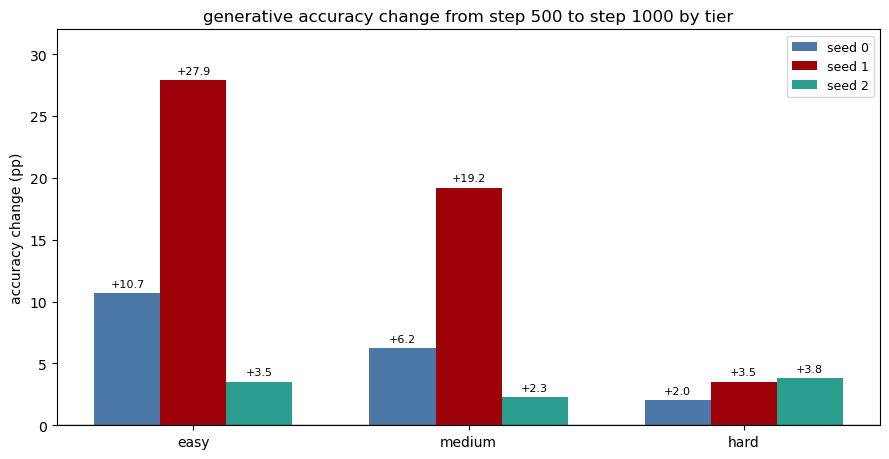

In [6]:
# compare continuation gains on each difficulty tier
tier_changes = {seed: [(paths[seed]['stats']['tiers'][tier][0] - paths[seed]['stats']['tiers'][tier][1]) * 100
                       for tier in TIERS] for seed in seeds}
x = np.arange(len(TIERS))
width = 0.24
fig, ax = plt.subplots(figsize=(9, 4.7))
for offset, seed in zip((-width, 0, width), seeds):
    bars = ax.bar(x + offset, tier_changes[seed], width, color=colours[seed], label=f'seed {seed}')
    ax.bar_label(bars, labels=[f'{v:+.1f}' for v in tier_changes[seed]], padding=3, fontsize=8)
ax.axhline(0, color='0.2', lw=1)
ax.set_xticks(x)
ax.set_xticklabels(TIERS)
ax.set_ylabel('accuracy change (pp)')
ax.set_ylim(0, 32)
ax.set_title('generative accuracy change from step 500 to step 1000 by tier')
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_tier_changes.png'), dpi=200, bbox_inches='tight')
plt.show()

## Paired answer changes

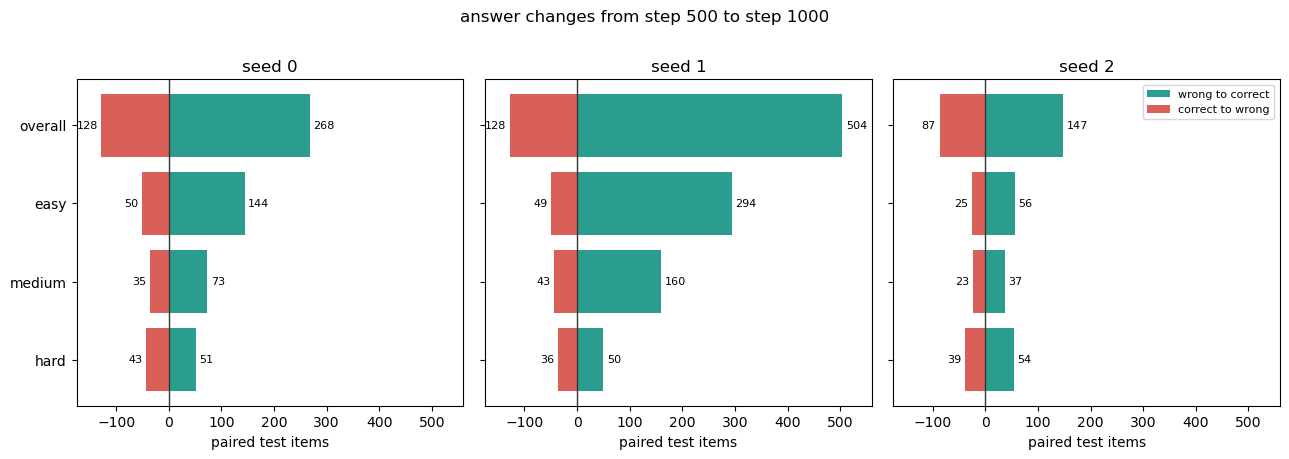

In [7]:
# count wrong-to-correct and correct-to-wrong changes for all continuations
def transition_counts(old, new):
    groups = ['overall'] + list(TIERS)
    gained, lost = [], []
    for group in groups:
        pairs = [(a, b) for a, b in zip(old, new)
                 if group == 'overall' or tier_of(a['subject']) == group]
        gained.append(sum((not a['correct']) and b['correct'] for a, b in pairs))
        lost.append(sum(a['correct'] and (not b['correct']) for a, b in pairs))
    return groups, gained, lost

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharex=True, sharey=True)
for ax, seed in zip(axes, seeds):
    groups, gained, lost = transition_counts(paths[seed]['rows500'], paths[seed]['rows1000'])
    y = np.arange(len(groups))
    ax.barh(y, gained, color='#2a9d8f', label='wrong to correct')
    ax.barh(y, [-v for v in lost], color='#d95f59', label='correct to wrong')
    for row, (up, down) in enumerate(zip(gained, lost)):
        ax.text(up + 7, row, str(up), va='center', fontsize=8)
        ax.text(-down - 7, row, str(down), va='center', ha='right', fontsize=8)
    ax.axvline(0, color='0.2', lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(groups)
    ax.set_title(f'seed {seed}')
    ax.set_xlabel('paired test items')
    ax.set_xlim(-175, 560)
axes[0].invert_yaxis()
axes[2].legend(fontsize=8, loc='upper right')
fig.suptitle('answer changes from step 500 to step 1000', y=1.01)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_paired_transitions.png'), dpi=200, bbox_inches='tight')
plt.show()

## Accuracy change by subject

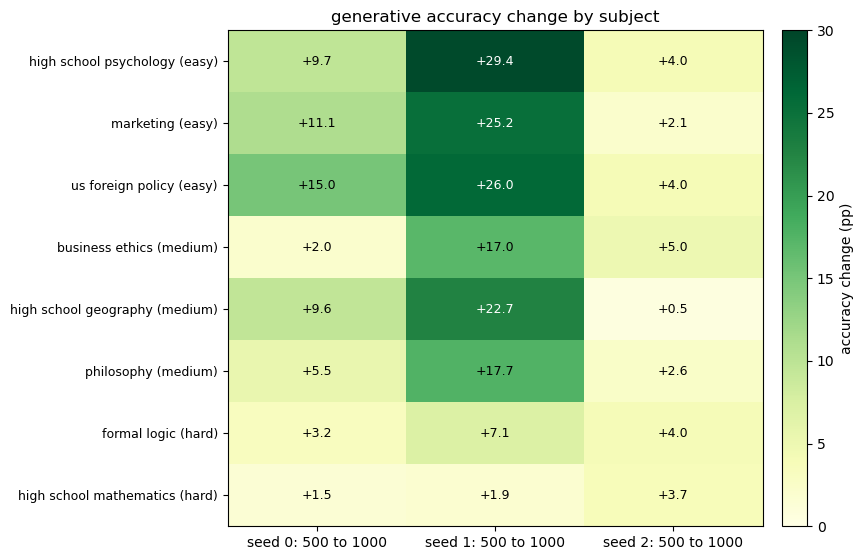

In [8]:
# compare subject-level accuracy changes across all continuations
subjects = sorted({r['subject'] for r in paths[0]['rows500']},
                  key=lambda s: (list(TIERS).index(tier_of(s)), s))
matrix = []
for subject in subjects:
    row = []
    for seed in seeds:
        before = [r['correct'] for r in paths[seed]['rows500'] if r['subject'] == subject]
        after = [r['correct'] for r in paths[seed]['rows1000'] if r['subject'] == subject]
        row.append((sum(after) / len(after) - sum(before) / len(before)) * 100)
    matrix.append(row)
matrix = np.array(matrix)

fig, ax = plt.subplots(figsize=(9, 5.7))
im = ax.imshow(matrix, cmap='YlGn', vmin=0, vmax=30, aspect='auto')
ax.set_xticks(np.arange(3))
ax.set_xticklabels([f'seed {s}: 500 to 1000' for s in seeds])
ax.set_yticks(np.arange(len(subjects)))
ax.set_yticklabels([f'{s.replace("_", " ")} ({tier_of(s)})' for s in subjects], fontsize=9)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        color = heatmap_text_color(im, matrix[i, j])
        ax.text(j, i, f'{matrix[i, j]:+.1f}', ha='center', va='center', fontsize=9, color=color)
cbar = fig.colorbar(im, ax=ax, pad=0.03)
cbar.set_label('accuracy change (pp)')
ax.set_title('generative accuracy change by subject')
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_subject_changes.png'), dpi=200, bbox_inches='tight')
plt.show()

## Output diagnostics

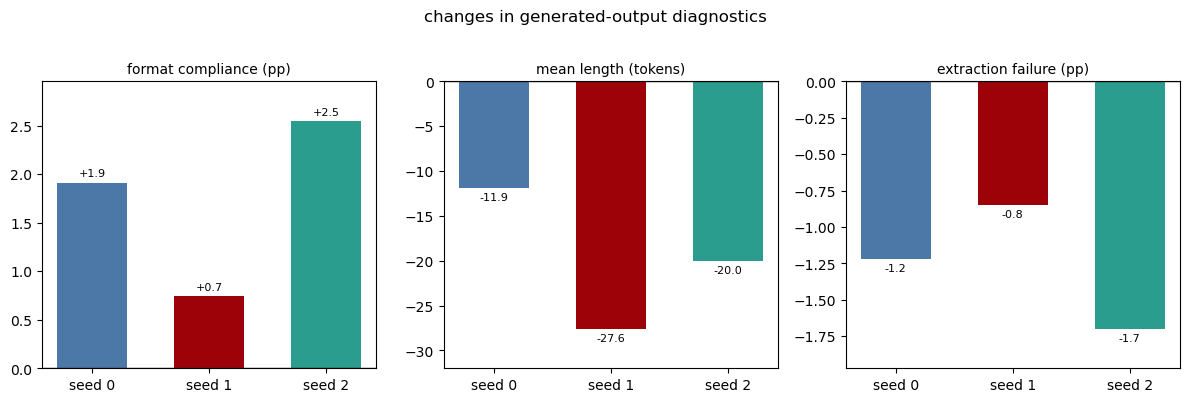

In [9]:
# compare output diagnostics before and after continuation
diagnostics = {
    'format compliance (pp)': [(paths[s]['stats']['fmt'][0] - paths[s]['stats']['fmt'][1]) * 100 for s in seeds],
    'mean length (tokens)': [paths[s]['stats']['len'][0] - paths[s]['stats']['len'][1] for s in seeds],
    'extraction failure (pp)': [(paths[s]['stats']['xfail'][0] - paths[s]['stats']['xfail'][1]) * 100 for s in seeds],
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, (name, values) in zip(axes, diagnostics.items()):
    bars = ax.bar([f'seed {s}' for s in seeds], values, color=[colours[s] for s in seeds], width=0.6)
    ax.axhline(0, color='0.2', lw=1)
    ax.bar_label(bars, labels=[f'{v:+.1f}' for v in values], padding=3, fontsize=8)
    ax.set_title(name, fontsize=10)
    ax.margins(y=0.16)
fig.suptitle('changes in generated-output diagnostics', y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_output_diagnostics.png'), dpi=200, bbox_inches='tight')
plt.show()

## Cross-referenced conclusion

All three restarted continuations improved generative accuracy. Seed 0 moved from 46.2% to 53.7% (+7.4 pp), seed 1 from 31.5% to 51.5% (+20.0 pp), and seed 2 from 50.6% to 53.8% (+3.2 pp). Every paired confidence interval stayed above zero, and every subject improved for every seed.

The seed spread fell from 19.1 pp at step 500 to 2.3 pp at step 1000. The recovered mean was 53.0%, close to the 53.4% MC-SFT mean, although seed 1 remained below the MC-SFT seed range. Probe changes stayed close to zero for all three seeds, so the gains mainly concern generated-answer behaviour rather than measured option preference.

These results support narrower conclusion that the restarted schedule recovered all three selected 0.5B artifacts and made their endpoints much more stable. They do not show that a clean 1000-step schedule would behave identically, that the result transfers to other scales, or that GRPO is generally better than MC-SFT.